# v13 PF画像の可視化 ― U-Netに入れる入力を目で確認

`create_pf_images_v13.py` が出力した `artifacts_v13/img/{well}.npz` を読み、3チャンネル
(順方向密度 / 逆方向密度 / GRコスト)を画像表示。**中心=順方向PF平均(y=0)**、
真のTVT経路(`target_rel`, train時)を赤線で重ねる。バンド外(mask=0)は薄表示。

- x軸 = MD方向(評価ゾーンの行)、y軸 = 中心からの相対TVT(ft)。
- 赤線が中央(0)付近に乗っていれば順方向PFが当たっている。大きく外れる所が逆方向/GRで救いたい所。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path(r"C:\Users\kosaka256\Documents\rogii_claude")
IMG_DIR = PROJECT / "v13" / "artifacts_v13" / "img"
MAN = PROJECT / "v13" / "artifacts_v13" / "manifest.csv"

man = pd.read_csv(MAN)
print(f"{len(man)} wells.  in_band率 mean={man['in_band_frac'].mean():.3f}" if "in_band_frac" in man else f"{len(man)} wells")
# 例: 当たり/外れの坑井を確認できるよう in_band でソートして候補表示
if "in_band_frac" in man:
    print("in_band 低い(難)坑井:", man.sort_values('in_band_frac').head(5)['well'].tolist())
    print("in_band 高い(易)坑井:", man.sort_values('in_band_frac').tail(5)['well'].tolist())

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\kosaka256\\Documents\\rogii_claude\\v13\\artifacts_v13\\manifest.csv'

well=000d7d20  img=(3, 201, 3836)  band=±100.0ft binw=1.0


C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\1696649649.py:28: UserWarning: Glyph 38918 (\N{CJK UNIFIED IDEOGRAPH-9806}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\1696649649.py:28: UserWarning: Glyph 26041 (\N{CJK UNIFIED IDEOGRAPH-65B9}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\1696649649.py:28: UserWarning: Glyph 21521 (\N{CJK UNIFIED IDEOGRAPH-5411}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\1696649649.py:28: UserWarning: Glyph 23494 (\N{CJK UNIFIED IDEOGRAPH-5BC6}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\1696649649.py:28: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka

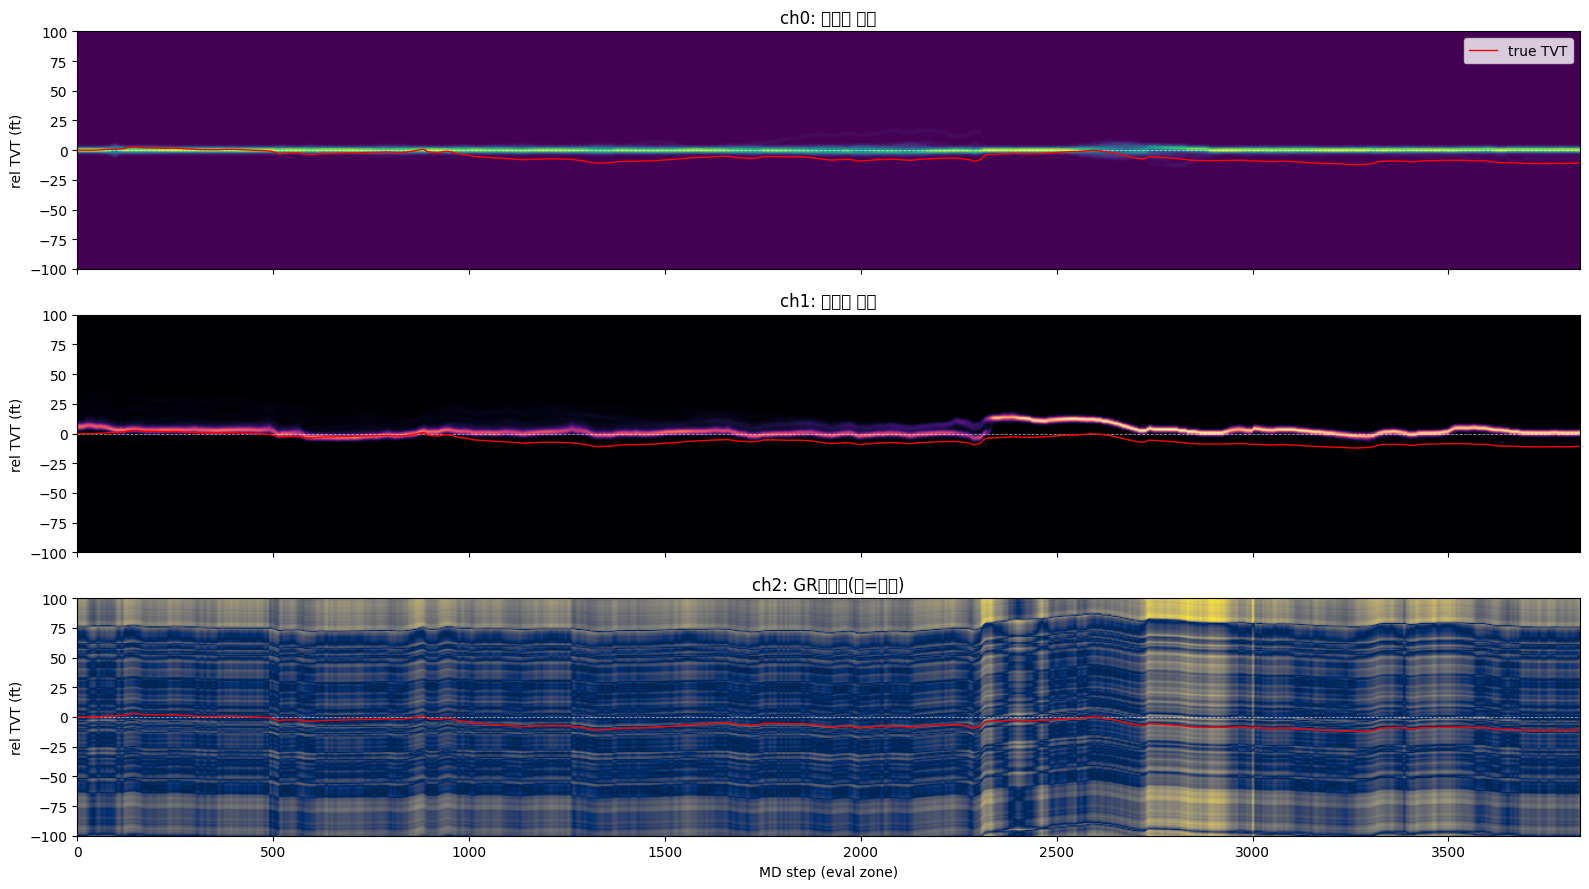

In [2]:
# 表示する坑井を選ぶ(manifest 先頭。WELL に well 名を入れて指定も可)
WELL = None
WELL = WELL or man["well"].iloc[0]
d = np.load(IMG_DIR / f"{WELL}.npz")
img = d["img"].astype(np.float32)          # (3,H,T)
H, T = img.shape[1], img.shape[2]
band = float(d["band"]); binw = float(d["binw"])
has_t = "target_rel" in d.files
print(f"well={WELL}  img={img.shape}  band=±{band}ft binw={binw}")

extent = [0, T, -band, band]               # x=MD index, y=相対TVT(ft)
titles = ["ch0: 順方向 密度", "ch1: 逆方向 密度", "ch2: GRコスト(小=整合)"]
cmaps  = ["viridis", "magma", "cividis"]

fig, axes = plt.subplots(3, 1, figsize=(16, 9), sharex=True)
for k, ax in enumerate(axes):
    ax.imshow(img[k], aspect="auto", origin="lower", extent=extent, cmap=cmaps[k])
    ax.axhline(0, color="white", lw=0.6, ls="--", alpha=0.6)   # center=順方向PF平均
    if has_t:
        tr = d["target_rel"].astype(np.float32)                # 真TVTの中心相対(ft)
        m = d["mask"].astype(bool) if "mask" in d.files else np.isfinite(tr)
        x = np.arange(T)
        ax.plot(x[m], tr[m], color="red", lw=1.0, label="true TVT")
        ax.plot(x[~m], np.clip(tr[~m], -band, band), color="red", lw=0.5, ls=":", alpha=0.5)
    ax.set_ylabel("rel TVT (ft)"); ax.set_title(titles[k]); ax.set_ylim(-band, band)
axes[-1].set_xlabel("MD step (eval zone)")
if has_t: axes[0].legend(loc="upper right")
plt.tight_layout(); plt.show()

C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\1411999282.py:14: UserWarning: Glyph 38918 (\N{CJK UNIFIED IDEOGRAPH-9806}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\1411999282.py:14: UserWarning: Glyph 26041 (\N{CJK UNIFIED IDEOGRAPH-65B9}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\1411999282.py:14: UserWarning: Glyph 21521 (\N{CJK UNIFIED IDEOGRAPH-5411}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\1411999282.py:14: UserWarning: Glyph 23494 (\N{CJK UNIFIED IDEOGRAPH-5BC6}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\1411999282.py:14: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka

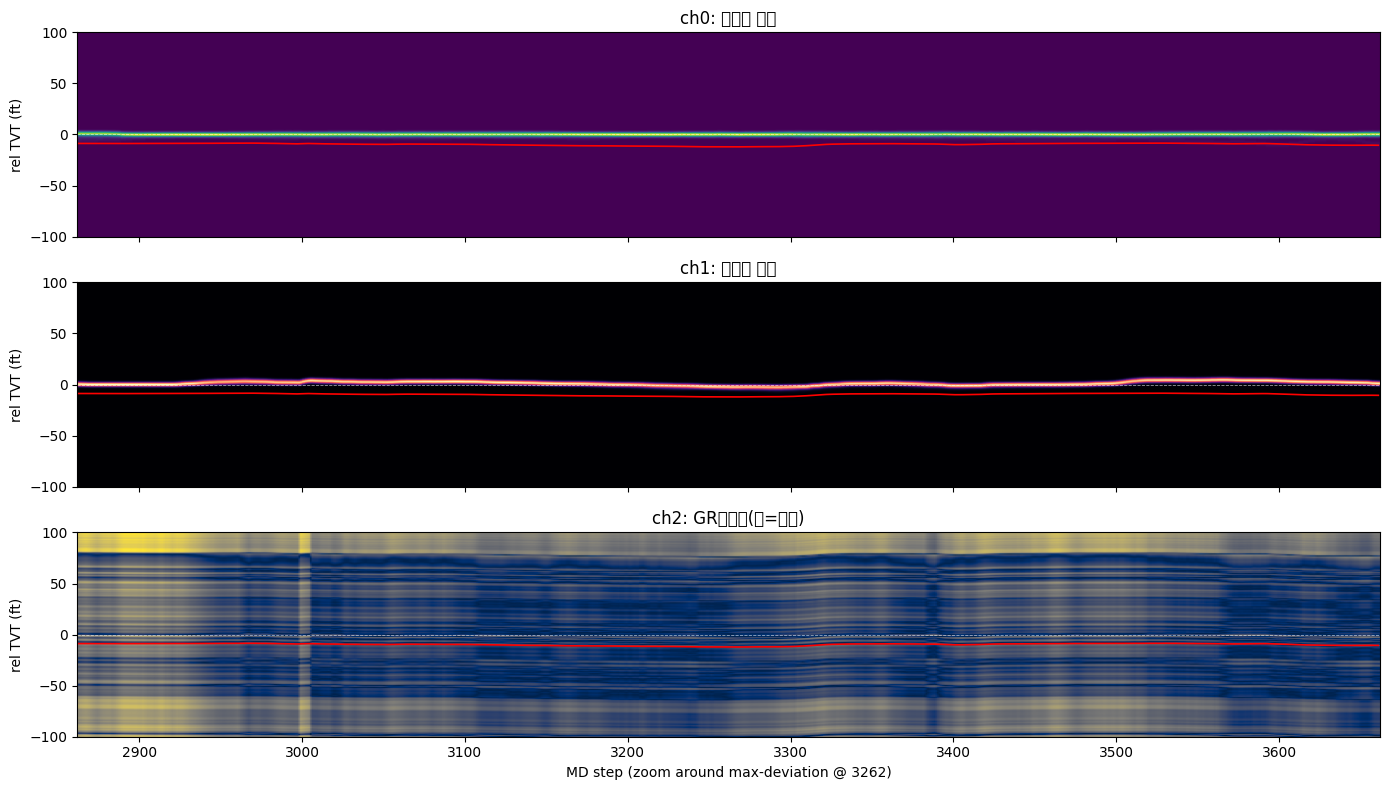

最大ズレ -12.2 ft @ step 3262


In [3]:
# 拡大表示: 真のTVTが中心から外れている区間を拡大して確認(train時)
if has_t:
    tr = d["target_rel"].astype(np.float32)
    j = int(np.nanargmax(np.abs(tr)))                      # 最も外れている位置
    lo, hi = max(0, j-400), min(T, j+400)
    fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
    for k, ax in enumerate(axes):
        ax.imshow(img[k, :, lo:hi], aspect="auto", origin="lower",
                  extent=[lo, hi, -band, band], cmap=cmaps[k])
        ax.axhline(0, color="white", lw=0.6, ls="--", alpha=0.6)
        ax.plot(np.arange(lo, hi), tr[lo:hi], color="red", lw=1.2)
        ax.set_ylabel("rel TVT (ft)"); ax.set_title(titles[k]); ax.set_ylim(-band, band)
    axes[-1].set_xlabel(f"MD step (zoom around max-deviation @ {j})")
    plt.tight_layout(); plt.show()
    print(f"最大ズレ {tr[j]:+.1f} ft @ step {j}")
else:
    print("test画像(ターゲット無し)")

## 元の per-seed 全波形を見る(密度に潰す前)

`fwd_traj`(順32本)/`bwd_traj`(逆128本)の生TVT波形を、中心(順方向PF平均)からの相対で重ね描き。
密度画像(ch0/ch1)は、これらを潰したもの。真のTVT(赤)に対し、順/逆の波形群がどう広がるかを確認。

C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\2150764666.py:19: UserWarning: Glyph 20840 (\N{CJK UNIFIED IDEOGRAPH-5168}) missing from font(s) DejaVu Sans.
  plt.legend(loc="upper right"); plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\2150764666.py:19: UserWarning: Glyph 27874 (\N{CJK UNIFIED IDEOGRAPH-6CE2}) missing from font(s) DejaVu Sans.
  plt.legend(loc="upper right"); plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\2150764666.py:19: UserWarning: Glyph 24418 (\N{CJK UNIFIED IDEOGRAPH-5F62}) missing from font(s) DejaVu Sans.
  plt.legend(loc="upper right"); plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\2150764666.py:19: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  plt.legend(loc="upper right"); plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\2150764666.py:19: UserWarning: Gly

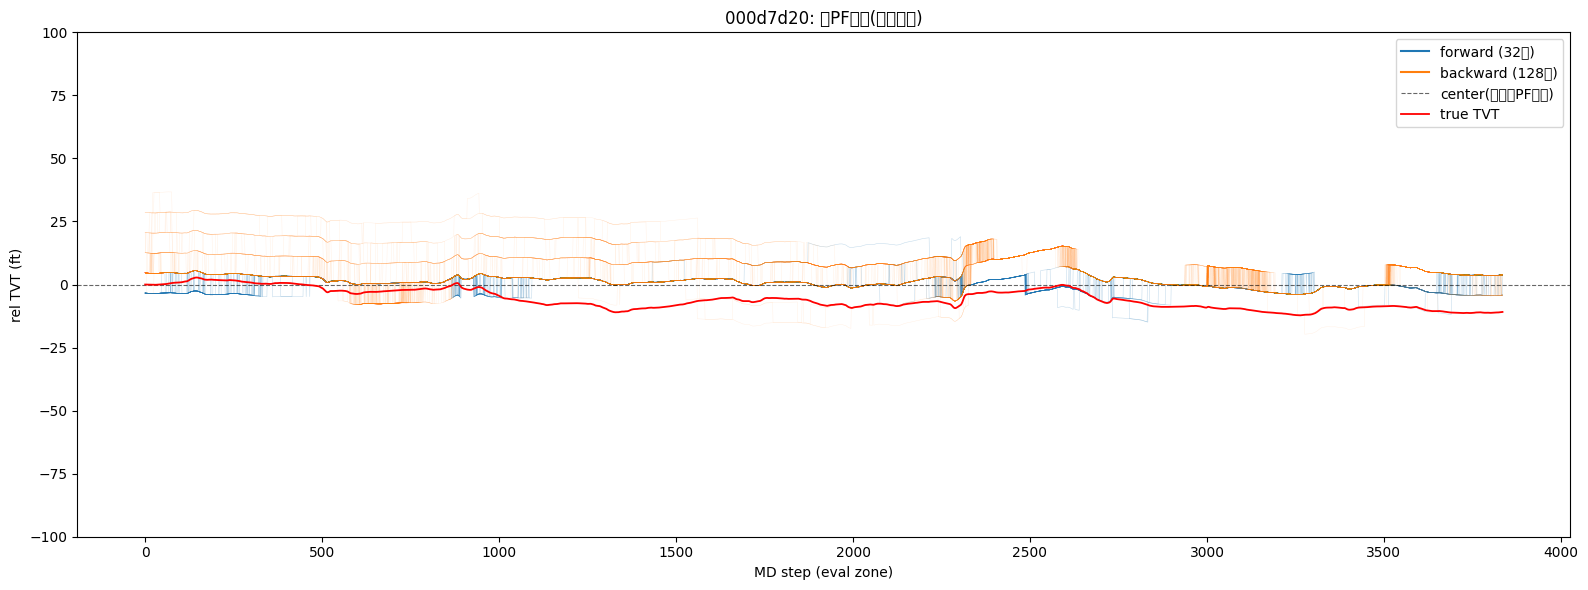

C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\2150764666.py:32: UserWarning: Glyph 20840 (\N{CJK UNIFIED IDEOGRAPH-5168}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\2150764666.py:32: UserWarning: Glyph 27874 (\N{CJK UNIFIED IDEOGRAPH-6CE2}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\2150764666.py:32: UserWarning: Glyph 24418 (\N{CJK UNIFIED IDEOGRAPH-5F62}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\2150764666.py:32: UserWarning: Glyph 25313 (\N{CJK UNIFIED IDEOGRAPH-62E1}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_32312\2150764666.py:32: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka

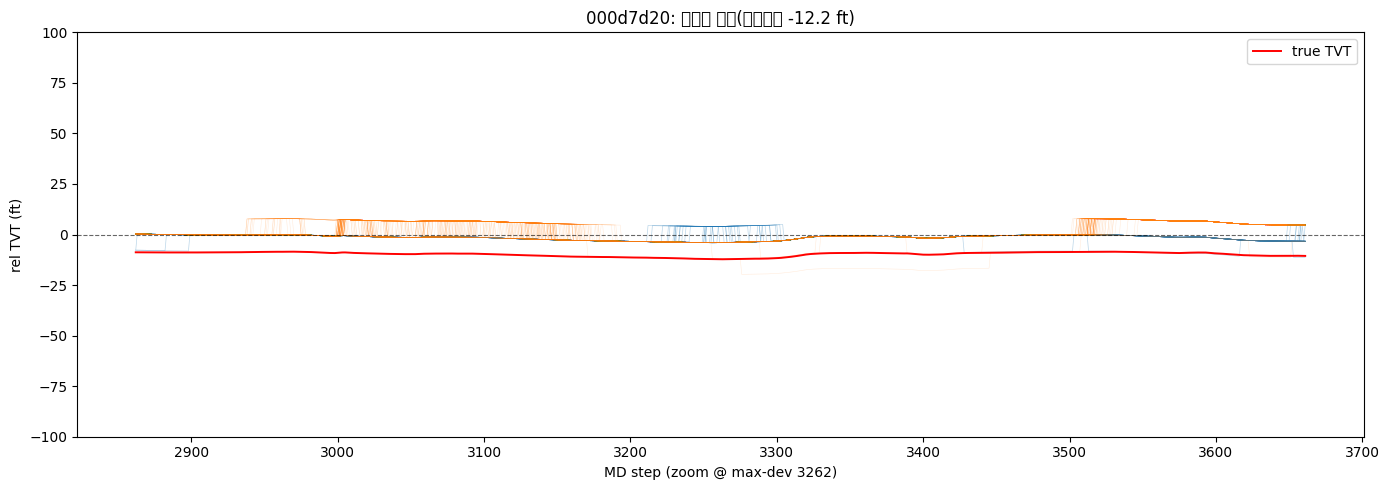

In [4]:
# 元の全波形(中心相対)。直前のセルで読み込んだ d / T / band / WELL / has_t を使用
fwd = d["fwd_traj"].astype(np.float32)      # (32, T) 絶対TVT
bwd = d["bwd_traj"].astype(np.float32)      # (128, T) 絶対TVT
center = d["center"].astype(np.float32)
x = np.arange(T)

plt.figure(figsize=(16, 6))
for s in range(fwd.shape[0]):
    plt.plot(x, fwd[s] - center, color="C0", lw=0.4, alpha=0.25)
for s in range(bwd.shape[0]):
    plt.plot(x, bwd[s] - center, color="C1", lw=0.3, alpha=0.12)
plt.plot([], [], color="C0", lw=1.5, label=f"forward ({fwd.shape[0]}本)")
plt.plot([], [], color="C1", lw=1.5, label=f"backward ({bwd.shape[0]}本)")
plt.axhline(0, color="k", lw=0.8, ls="--", alpha=0.6, label="center(順方向PF平均)")
if has_t:
    plt.plot(x, d["target_rel"].astype(np.float32), color="red", lw=1.3, label="true TVT")
plt.ylim(-band, band); plt.xlabel("MD step (eval zone)"); plt.ylabel("rel TVT (ft)")
plt.title(f"{WELL}: 全PF波形(中心相対)")
plt.legend(loc="upper right"); plt.tight_layout(); plt.show()

# 最大ズレ区間を拡大(train時)
if has_t:
    tr = d["target_rel"].astype(np.float32)
    j = int(np.nanargmax(np.abs(tr))); lo, hi = max(0, j-400), min(T, j+400)
    plt.figure(figsize=(14, 5))
    for s in range(fwd.shape[0]): plt.plot(np.arange(lo,hi), fwd[s,lo:hi]-center[lo:hi], color="C0", lw=0.5, alpha=0.3)
    for s in range(bwd.shape[0]): plt.plot(np.arange(lo,hi), bwd[s,lo:hi]-center[lo:hi], color="C1", lw=0.4, alpha=0.15)
    plt.plot(np.arange(lo,hi), tr[lo:hi], color="red", lw=1.4, label="true TVT")
    plt.axhline(0, color="k", lw=0.8, ls="--", alpha=0.6)
    plt.ylim(-band, band); plt.xlabel(f"MD step (zoom @ max-dev {j})"); plt.ylabel("rel TVT (ft)")
    plt.title(f"{WELL}: 全波形 拡大(最大ズレ {tr[j]:+.1f} ft)"); plt.legend(loc="upper right")
    plt.tight_layout(); plt.show()